# Klasifikasi Sentimen Komentar KDMP dengan SVM

**Soal No. 4:** Implementasi algoritma klasifikasi pada dataset pilihan menggunakan Python, evaluasi model, dan laporan analisis hasil.

- **Algoritma:** Support Vector Machine (Linear SVM) + representasi teks TF-IDF
- **Dataset:** Komentar TikTok seputar Koperasi Merah Putih (KDMP), 3 kelas: `positif`, `negatif`, `netral`
- **Penanganan imbalance:** undersampling kelas `netral` + `class_weight='balanced'`

## 1. Persiapan & Memuat Dataset

Dataset berisi komentar TikTok tentang **Koperasi Desa/Kelurahan Merah Putih (KDMP)** yang sudah diberi label sentimen (`positif`, `negatif`, `netral`).

> **Jika dijalankan di Google Colab:** upload file `KDMP_berlabel_perbaikan.csv` ke sesi Colab (panel kiri → Files), lalu ubah `DATA_PATH` bila perlu.

In [ ]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [ ]:
DATA_PATH = "KDMP_berlabel_perbaikan.csv"

df_raw = pd.read_csv(DATA_PATH)
print("Ukuran dataset awal :", df_raw.shape)
print("Kolom               :", list(df_raw.columns))
df_raw[["comment", "sentimen"]].head()

Ukuran dataset awal : (220051, 9)
Kolom               : ['video_id', 'comment_id', 'parent_comment_id', 'level', 'username', 'nickname', 'comment', 'create_time', 'sentimen']


,comment,sentimen
0,Beliau bilang untung nya 2 m ?,negatif
1,Makasih Mas,positif
2,Gimana untung nya 2 m..barang yg di jual ajh g...,negatif
3,[Sticker] dibilang Makasih Mas udah 2M itu,positif
4,😳😳😳,netral


Missing value pada kolom penting:
comment     304
sentimen      0
dtype: int64 

Distribusi label awal:
sentimen
netral     144617
negatif     59206
positif     16228
Name: count, dtype: int64


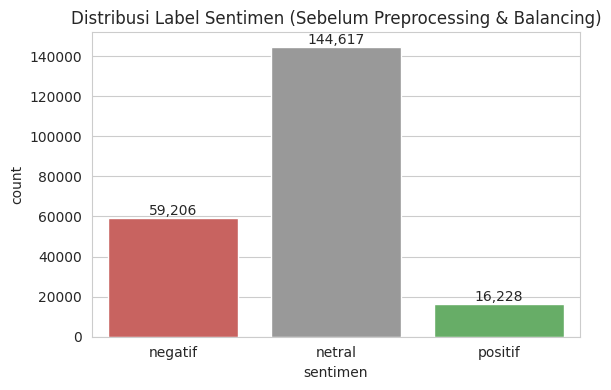

In [ ]:
print("Missing value pada kolom penting:")
print(df_raw[["comment", "sentimen"]].isna().sum(), "\n")
print("Distribusi label awal:")
print(df_raw["sentimen"].value_counts())

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_raw, x="sentimen", order=["negatif", "netral", "positif"],
              palette=["#d9534f", "#999999", "#5cb85c"], ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Distribusi Label Sentimen (Sebelum Preprocessing & Balancing)")
plt.tight_layout(); plt.show()

## 2. Preprocessing Teks

Langkah-langkah:
1. Hapus komentar kosong (`NaN`).
2. *Case folding* (huruf kecil), hapus tag `[Sticker]`, URL, mention, angka, tanda baca, dan emoji.
3. Rapikan huruf berulang (`mantaaaap` → `mantaap`).
4. Normalisasi kata gaul/singkatan umum (`gak`→`tidak`, `yg`→`yang`, dst.).
5. Hapus *stopword* umum (kata negasi seperti `tidak`, `bukan`, `belum` sengaja **dipertahankan** karena penting untuk sentimen). Emoji ikut terhapus pada tahap ini.
6. **Hapus duplikat** teks yang sudah dibersihkan. Pada data ini banyak komentar identik (mis. "setuju", "kocak"); jika dibiarkan, komentar yang sama bisa muncul di data latih *dan* data uji sehingga evaluasi menjadi terlalu optimis (*data leakage*).

In [ ]:
SLANG = {
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "ngga": "tidak", "gk": "tidak",
    "tdk": "tidak", "tak": "tidak", "enggak": "tidak", "engga": "tidak",
    "yg": "yang", "dgn": "dengan", "dg": "dengan", "utk": "untuk", "untk": "untuk",
    "krn": "karena", "karna": "karena", "sdh": "sudah", "udh": "sudah", "udah": "sudah",
    "blm": "belum", "blom": "belum", "jd": "jadi", "dr": "dari", "sy": "saya",
    "aku": "saya", "gue": "saya", "gw": "saya", "org": "orang", "orng": "orang",
    "klo": "kalau", "kalo": "kalau", "kl": "kalau", "emg": "memang", "emang": "memang",
    "tp": "tapi", "tpi": "tapi", "dlm": "dalam", "pake": "pakai", "bs": "bisa",
    "lg": "lagi", "lgi": "lagi", "trs": "terus", "sm": "sama", "hrs": "harus",
    "bgt": "banget", "bngt": "banget", "aja": "saja", "ajh": "saja", "sj": "saja",
    "skrg": "sekarang", "bkn": "bukan", "jgn": "jangan", "jgan": "jangan",
    "mksh": "terima kasih", "makasih": "terima kasih", "thx": "terima kasih",
    "pemerintah": "pemerintah", "pmrth": "pemerintah", "kdmp": "kdmp",
    "wkwk": "wkwk", "wkwkwk": "wkwk", "wkwkwkwk": "wkwk", "hehe": "hehe",
}

# Kata negasi/penguat sentimen JANGAN dibuang karena mengubah makna kalimat
NEGATION = {"tidak", "bukan", "belum", "jangan", "tanpa", "kurang", "banget", "sangat", "bisa", "mau"}
STOPWORDS = {
    "yang", "dan", "di", "ke", "dari", "ini", "itu", "dengan", "untuk", "pada", "adalah",
    "ya", "nya", "si", "sih", "dong", "deh", "lah", "kah", "pun", "oleh", "atau", "juga",
    "saja", "ada", "akan", "sudah", "lagi", "saya", "kita", "kami", "dia", "mereka",
    "kan", "nih", "tuh", "mah", "kok", "yaa", "yah", "nah", "pak", "bu", "mas", "mbak",
    "kalau", "karena", "jadi", "sama", "dalam", "bagi", "para", "sebagai", "dll",
} - NEGATION


def clean_text(text, remove_stopwords=False):
    t = str(text).lower()
    t = re.sub(r"\[[^\]]*\]", " ", t)            # [Sticker], [Foto], dsb.
    t = re.sub(r"http\S+|www\.\S+", " ", t)        # URL
    t = re.sub(r"@\w+", " ", t)                    # mention
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)           # huruf berulang >2
    t = re.sub(r"[^a-z\s]", " ", t)                # angka, tanda baca, emoji
    tokens = [SLANG.get(w, w) for w in t.split()]
    tokens = " ".join(tokens).split()              # pecah ulang (mis. "terima kasih")
    if remove_stopwords:
        tokens = [w for w in tokens if w not in STOPWORDS]
    return " ".join(tokens)

In [ ]:
REMOVE_STOPWORDS = True

df = df_raw.dropna(subset=["comment", "sentimen"]).copy()
df["clean"] = df["comment"].map(lambda x: clean_text(x, remove_stopwords=REMOVE_STOPWORDS))

n0 = len(df)
df = df[df["clean"].str.len() >= 3]                 # buang komentar yang jadi kosong / terlalu pendek
n1 = len(df)
df = df.drop_duplicates(subset="clean", keep="first")
n2 = len(df)

print(f"Setelah buang NaN         : {n0:,}")
print(f"Setelah buang teks kosong : {n1:,}")
print(f"Setelah buang duplikat    : {n2:,}")
print()
print(df["sentimen"].value_counts())
df[["comment", "clean", "sentimen"]].sample(8, random_state=1)

Setelah buang NaN         : 219,747
Setelah buang teks kosong : 206,876
Setelah buang duplikat    : 107,868

sentimen
netral     67958
negatif    30999
positif     8911
Name: count, dtype: int64


,comment,clean,sentimen
91757,harga sesuai mood,harga sesuai mood,netral
52928,Boleh ketawa gk🤣🤣🤣🤣🤣,boleh ketawa tidak,netral
82558,anjir mendingan warung Madura,anjir mendingan warung madura,netral
34428,toko ate bangkrut ta iki,toko ate bangkrut ta iki,negatif
10135,"ini kan di pucangan, montong kan",pucangan montong,netral
112598,"impor apa bgstt, yg punya alfa indomaret juga ...",impor apa bgstt punya alfa indomaret orang ind...,negatif
46608,biar ngga corona,biar tidak corona,netral
58805,[Sticker] gak penting buat apa coba,tidak penting buat apa coba,netral


## 3. Penyeimbangan Kelas (Undersampling Kelas Netral)

Kelas **netral** jauh lebih banyak dibanding kelas lain. Agar model tidak condong memprediksi "netral", jumlah data netral **dikurangi secara acak (random undersampling)** hingga sama dengan jumlah kelas terbanyak berikutnya (yaitu `negatif`).

Kelas `positif` tetap lebih sedikit, sehingga selain undersampling, pembobotan kelas (*class weight*) juga dipakai saat pelatihan (`class_weight='balanced'`).

Target jumlah kelas netral: 30,999

          sebelum  sesudah
sentimen                  
netral      67958    30999
negatif     30999    30999
positif      8911     8911


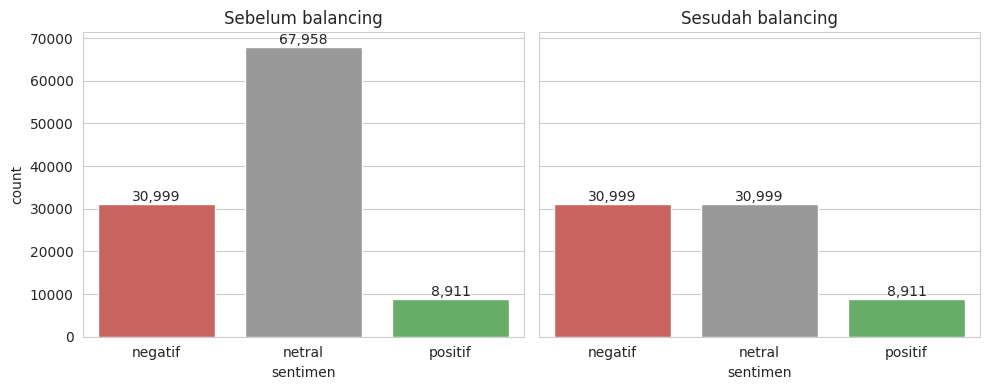

In [ ]:
SEED = 42
n_target = df[df["sentimen"] != "netral"]["sentimen"].value_counts().max()

df_netral = df[df["sentimen"] == "netral"].sample(n=min(n_target, (df["sentimen"] == "netral").sum()),
                                                   random_state=SEED)
df_bal = pd.concat([df[df["sentimen"] != "netral"], df_netral]).sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"Target jumlah kelas netral: {n_target:,}\n")
cmp = pd.DataFrame({"sebelum": df["sentimen"].value_counts(), "sesudah": df_bal["sentimen"].value_counts()})
print(cmp)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
order = ["negatif", "netral", "positif"]
colors = ["#d9534f", "#999999", "#5cb85c"]
for ax, d, ttl in zip(axes, [df, df_bal], ["Sebelum balancing", "Sesudah balancing"]):
    sns.countplot(data=d, x="sentimen", order=order, palette=colors, ax=ax)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
    ax.set_title(ttl)
plt.tight_layout(); plt.show()

## 4. Pembagian Data (Train / Test)

Data dibagi **80% latih : 20% uji** dengan *stratified split* agar proporsi tiap kelas sama di kedua bagian.

In [ ]:
X = df_bal["clean"]
y = df_bal["sentimen"]
LABELS = ["negatif", "netral", "positif"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Data latih:", X_train.shape[0], "| Data uji:", X_test.shape[0])
print("\nDistribusi data latih:\n", y_train.value_counts())
print("\nDistribusi data uji:\n", y_test.value_counts())

Data latih: 56727 | Data uji: 14182

Distribusi data latih:
 sentimen
netral     24799
negatif    24799
positif     7129
Name: count, dtype: int64

Distribusi data uji:
 sentimen
negatif    6200
netral     6200
positif    1782
Name: count, dtype: int64


## 5. Pembangunan Model: TF-IDF + Linear SVM

- **TF-IDF** dengan unigram + bigram (`ngram_range=(1,2)`), `min_df=2`, `sublinear_tf=True`.
- **LinearSVC** dipilih karena cepat dan efektif untuk data teks berdimensi tinggi.
- **Tuning hyperparameter** `C` dan `ngram_range` menggunakan `GridSearchCV` (3-fold, metrik **macro-F1** supaya setiap kelas dihitung setara).

In [ ]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2, sublinear_tf=True, max_features=100_000)),
    ("svm", LinearSVC(class_weight="balanced", random_state=SEED, max_iter=5000)),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "svm__C": [0.05, 0.1, 0.5, 1, 2],
}

grid = GridSearchCV(pipe, param_grid, scoring="f1_macro",
                    cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("Parameter terbaik :", grid.best_params_)
print(f"Macro-F1 CV terbaik: {grid.best_score_:.4f}")
pd.DataFrame(grid.cv_results_)[["param_tfidf__ngram_range", "param_svm__C", "mean_test_score", "std_test_score"]] \
  .sort_values("mean_test_score", ascending=False).head(10)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


Parameter terbaik : {'svm__C': 0.5, 'tfidf__ngram_range': (1, 1)}
Macro-F1 CV terbaik: 0.8634


,param_tfidf__ngram_range,param_svm__C,mean_test_score,std_test_score
4,"(1, 1)",0.50,0.863394,0.001667
6,"(1, 1)",1.00,0.862064,0.000841
5,"(1, 2)",0.50,0.857497,0.000951
8,"(1, 1)",2.00,0.856769,0.001124
7,"(1, 2)",1.00,0.854101,0.002096
2,"(1, 1)",0.10,0.849151,0.001196
9,"(1, 2)",2.00,0.847722,0.002860
3,"(1, 2)",0.10,0.842926,0.002030
0,"(1, 1)",0.05,0.834581,0.001394
1,"(1, 2)",0.05,0.828215,0.003183


## 6. Evaluasi Model pada Data Uji

Accuracy        : 0.8545
Macro Precision : 0.8585


Macro Recall    : 0.8730
Macro F1-score  : 0.8619
Weighted F1     : 0.8527



              precision    recall  f1-score   support

     negatif     0.9038    0.7577    0.8244      6200
      netral     0.8184    0.9287    0.8701      6200
     positif     0.8532    0.9327    0.8912      1782

    accuracy                         0.8545     14182
   macro avg     0.8585    0.8730    0.8619     14182
weighted avg     0.8601    0.8545    0.8527     14182



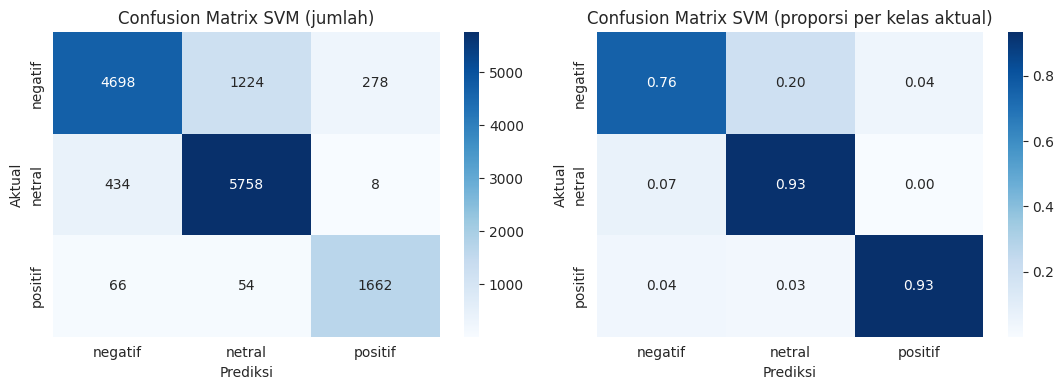

In [ ]:
def plot_cm(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=axes[0])
    axes[0].set_title(f"{title} (jumlah)"); axes[0].set_xlabel("Prediksi"); axes[0].set_ylabel("Aktual")
    sns.heatmap(cm_pct, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=axes[1])
    axes[1].set_title(f"{title} (proporsi per kelas aktual)"); axes[1].set_xlabel("Prediksi"); axes[1].set_ylabel("Aktual")
    plt.tight_layout(); plt.show()

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(f"Accuracy        : {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro Precision : {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Macro Recall    : {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"Macro F1-score  : {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Weighted F1     : {f1_score(y_test, y_pred, average='weighted'):.4f}\n")
print(classification_report(y_test, y_pred, labels=LABELS, digits=4))

plot_cm(y_test, y_pred, LABELS, "Confusion Matrix SVM")

### 6.1 Pengaruh Balancing: Perbandingan dengan Model Tanpa Balancing

Sebagai pembanding, model yang sama dilatih pada data **tanpa undersampling** (netral tetap dominan, tanpa class weight). Karena distribusi data uji berbeda, bandingkan terutama **recall per kelas** dan **macro-F1**.

In [ ]:
X_all, y_all = df["clean"], df["sentimen"]
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)

base = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2, sublinear_tf=True, max_features=100_000,
                              ngram_range=grid.best_params_["tfidf__ngram_range"])),
    ("svm", LinearSVC(C=grid.best_params_["svm__C"], random_state=SEED, max_iter=5000)),
]).fit(Xa_tr, ya_tr)
ya_pred = base.predict(Xa_te)

rec_base = recall_score(ya_te, ya_pred, labels=LABELS, average=None)
rec_bal = recall_score(y_test, y_pred, labels=LABELS, average=None)
cmp = pd.DataFrame({"Recall tanpa balancing": rec_base, "Recall dengan balancing": rec_bal}, index=LABELS)
cmp.loc["MACRO-F1"] = [f1_score(ya_te, ya_pred, average="macro"), f1_score(y_test, y_pred, average="macro")]
cmp.round(4)

,Recall tanpa balancing,Recall dengan balancing
negatif,0.7045,0.7577
netral,0.9859,0.9287
positif,0.9040,0.9327
MACRO-F1,0.8796,0.8619


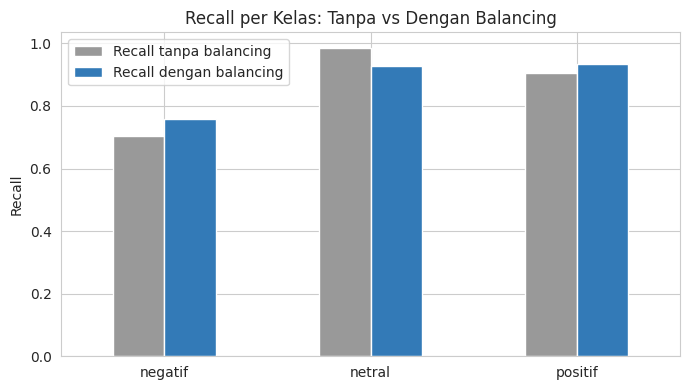

In [ ]:
cmp.iloc[:3].plot(kind="bar", figsize=(7, 4), color=["#999999", "#337ab7"])
plt.title("Recall per Kelas: Tanpa vs Dengan Balancing"); plt.ylabel("Recall"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 7. Interpretasi Model: Kata Paling Berpengaruh per Kelas

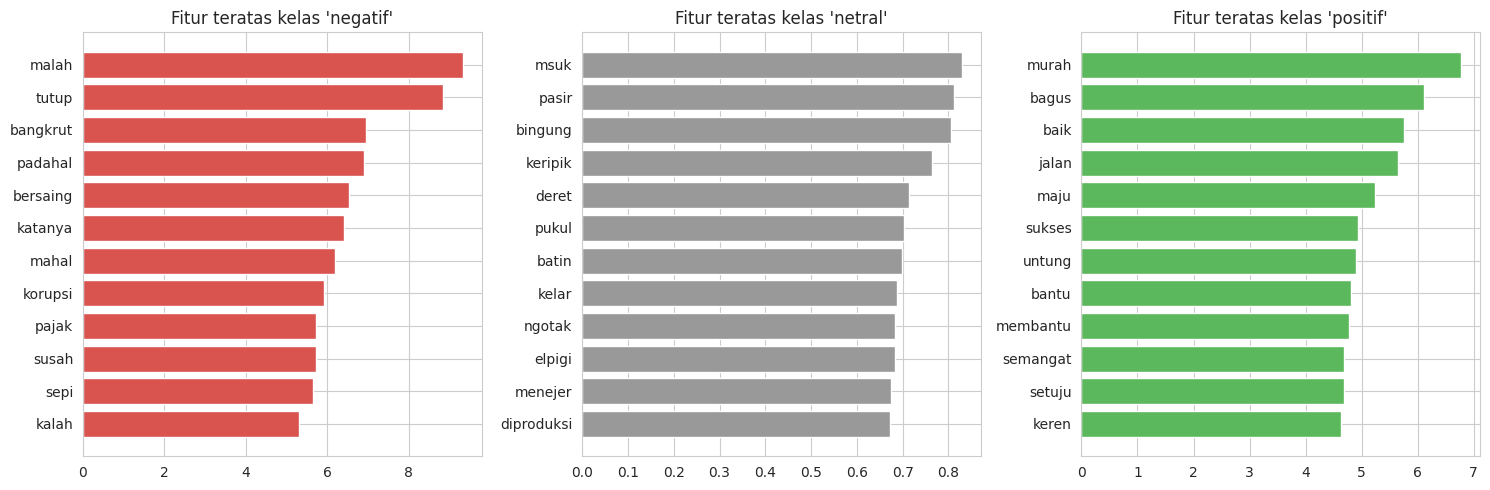

In [ ]:
tfidf = best_model.named_steps["tfidf"]
svm = best_model.named_steps["svm"]
feat = np.array(tfidf.get_feature_names_out())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, (cls, ax, col) in enumerate(zip(svm.classes_, axes, ["#d9534f", "#999999", "#5cb85c"])):
    top = np.argsort(svm.coef_[i])[-12:]
    ax.barh(feat[top], svm.coef_[i][top], color=col)
    ax.set_title(f"Fitur teratas kelas '{cls}'")
plt.tight_layout(); plt.show()

## 8. Analisis Kesalahan (Error Analysis)

In [ ]:
err = pd.DataFrame({"komentar": X_test.values, "aktual": y_test.values, "prediksi": y_pred})
err = err[err.aktual != err.prediksi]
print(f"Jumlah salah prediksi: {len(err):,} dari {len(y_test):,} ({len(err)/len(y_test):.1%})\n")
print(pd.crosstab(err.aktual, err.prediksi))
pd.set_option("display.max_colwidth", 120)
err.sample(10, random_state=3)

Jumlah salah prediksi: 2,064 dari 14,182 (14.6%)

prediksi  negatif  netral  positif
aktual                            
negatif         0    1224      278
netral        434       0        8
positif        66      54        0


,komentar,aktual,prediksi
10736,berasa pinter ngomong gini,negatif,netral
11288,lowongan kerja supirnya tidak,negatif,netral
9580,bulan koperasi tapi mini market gedung sebesar pengamanannya satpam lain,negatif,netral
9160,stopbelanja,positif,netral
12895,anda ngerti modal untung warung tangan keberapa,negatif,positif
2905,punya gubernur,negatif,netral
8705,pasti nanti rugike pertamina,negatif,netral
13393,ordal tidak kak,negatif,netral
28,adanya koperasi desa indomaret alfa midi secara perlahan membunuh ekonomi toko toko kecil kenapa tidak pernah terfik...,netral,negatif
5481,apa belum kelar drama per mbgan muncul,negatif,netral


## 9. Menyimpan Model & Contoh Prediksi

In [ ]:
joblib.dump(best_model, "model_svm_sentimen_kdmp.joblib")

contoh = [
    "koperasi merah putih sangat membantu warga desa, semoga sukses",
    "cuma bikin boros anggaran negara, nanti juga bangkrut",
    "tokonya buka jam berapa ya",
]
for k, p in zip(contoh, best_model.predict([clean_text(c, True) for c in contoh])):
    print(f"[{p:8s}] {k}")

[positif ] koperasi merah putih sangat membantu warga desa, semoga sukses
[negatif ] cuma bikin boros anggaran negara, nanti juga bangkrut
[negatif ] tokonya buka jam berapa ya


## 10. Laporan Analisis Hasil (SVM)

### 10.1 Ringkasan
| Metrik (data uji, 14.182 komentar) | Nilai |
|---|---|
| Accuracy | **0,8545** |
| Macro Precision / Recall | 0,8585 / 0,8730 |
| Macro F1-score | **0,8619** |
| Hyperparameter terbaik | `C = 0.5`, TF-IDF unigram |

Dataset awal 220.051 komentar. Setelah pembersihan dan penghapusan duplikat tersisa 107.868 komentar unik (netral 67.958, negatif 30.999, positif 8.911). Kelas netral lalu di-*undersampling* menjadi 30.999 (sama dengan negatif), sehingga data akhir berjumlah 70.909.

### 10.2 Analisis per kelas
- **Positif**: recall tertinggi (0,933), F1 0,891. Kelas ini punya kosakata yang relatif khas sehingga lebih mudah dikenali (lihat grafik fitur teratas pada bagian 7).
- **Netral**: recall 0,929 tetapi presisi 0,818, artinya banyak komentar kelas lain yang "tertarik" ke netral.
- **Negatif**: presisi tinggi (0,904) tetapi recall paling rendah (0,758). Model berhati-hati melabeli negatif dan sering melewatkannya.

### 10.3 Analisis kesalahan
Dari 2.064 salah prediksi, kesalahan terbesar adalah **negatif yang diprediksi netral (1.224 kasus, ±59%)**, disusul netral yang diprediksi negatif (434 kasus). Kesalahan yang melibatkan kelas positif jauh lebih sedikit (120 kasus). Jadi kebingungan model terutama terjadi di batas **negatif ↔ netral**. Banyak komentar negatif bersifat sindiran, singkat, atau tanpa kata bernada negatif eksplisit, dan emoji (yang sering membawa nada sentimen) ikut terhapus saat preprocessing.

### 10.4 Pengaruh balancing
| | Tanpa balancing | Dengan balancing |
|---|---|---|
| Recall negatif | 0,705 | **0,758** |
| Recall netral | 0,986 | 0,929 |
| Recall positif | 0,904 | **0,933** |

Tanpa balancing, model sangat condong ke netral (recall 0,986) dan mengorbankan negatif. Dengan balancing, recall negatif dan positif naik, sedangkan recall netral turun, yaitu *trade-off* yang memang diharapkan. Macro-F1 tanpa balancing (0,880) tampak lebih tinggi daripada dengan balancing (0,862), tetapi **keduanya tidak bisa dibandingkan langsung** karena diukur pada data uji yang distribusinya berbeda (data uji tanpa balancing didominasi kelas netral yang mudah ditebak). Gunakan recall per kelas sebagai pembanding utama.

### 10.5 Keterbatasan & saran
- Label mengandung ambiguitas (terutama netral vs negatif), sehingga ada batas atas performa yang bisa dicapai.
- TF-IDF tidak memahami konteks/sindiran. Contoh uji "tokonya buka jam berapa ya" (seharusnya netral) diprediksi negatif.
- Saran: pertahankan emoji sebagai fitur, tambahkan stemming (Sastrawi), atau gunakan model berbasis transformer berbahasa Indonesia (mis. IndoBERT).

### 10.6 Kesimpulan
Linear SVM dengan TF-IDF memberikan hasil yang kuat (akurasi ±85%, macro-F1 ±0,86), cepat dilatih, dan mudah diinterpretasi. Penyeimbangan kelas berhasil mengurangi kecondongan ke kelas netral.